# Spotify Tracks · Predicción de popularidad de canciones
**MLY1101 – Machine Learning · Evaluación Parcial N°2 (Caso C)**

Este notebook sigue las etapas de CRISP-DM y reproduce lo descrito en el `README.md`:
1. Problema de negocio y KPIs
2. Carga de datos y target
3. Análisis exploratorio (EDA)
4. Preparación de datos
5. Modelado supervisado: XGBoost (clasificación y regresión) y Random Forest (modelo de comparación)
6. Modelado no supervisado: segmentación de canciones con K-Means
7. Interpretación de resultados y recomendaciones de negocio

**Cómo ejecutarlo:** instalar `requirements.txt` y correr todas las celdas en orden (*Run All*).

## 1. Problema de negocio

Las plataformas y sellos musicales deben decidir qué canciones promocionar, pero hoy lo hacen con criterio subjetivo.
**Problema:** clasificar si una canción será popular (`popularity > 70`) usando sus características de audio, duración, si es explícita y su género.
**Uso esperado:** el modelo entrega un ranking de candidatas para apoyar al equipo de promoción, no reemplaza su decisión.

## 2. KPIs

| Tipo | KPI | Qué mide |
|---|---|---|
| Clasificación (principal) | **F1-score** | Equilibrio entre Precision y Recall en la clase "popular" |
| Clasificación | **Precision** | De las canciones que el modelo marca como populares, cuántas realmente lo son |
| Clasificación | **Recall** | De las canciones realmente populares, cuántas logra detectar |
| Clasificación (apoyo) | **PR-AUC** | Calidad del ranking sin depender del umbral |
| Regresión | **MAE / RMSE** | Error promedio (y error con castigo a los grandes) en puntos de popularidad |
| No supervisado | **Silueta / Inercia** | Qué tan separados y compactos quedan los grupos de canciones |
| No supervisado (negocio) | **% de populares por cluster** | Si algún perfil musical concentra más (o menos) éxitos que el promedio (~4 %) |

No usamos *accuracy*: solo ~4 % de las canciones es popular, así que predecir "nadie es popular" ya daría ~96 % sin ser útil.

In [1]:
# Librerías del proyecto (si falta alguna: pip install -r requirements.txt)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Parámetros globales: semilla (reproducibilidad) y umbral de popularidad
SEED = 42
THRESHOLD_POPULAR = 70

# Rutas del proyecto: el notebook vive en notebooks/, los datos en data/
BASE = Path("..") if Path("../data").exists() else Path(".")
DATA_PATH = BASE / "data" / "Spotify_Tracks_Dataset.csv"
IMG_DIR, MODELS_DIR = BASE / "images", BASE / "models"
IMG_DIR.mkdir(exist_ok=True); MODELS_DIR.mkdir(exist_ok=True)

## 3. Carga de datos y target

Dataset público *Spotify Tracks* con 114.000 filas y 21 columnas (audio, duración, género, popularidad).
El target `is_popular` vale 1 si `popularity > 70` y 0 en otro caso.

In [2]:
# Carga el CSV y crea el target binario is_popular (1 = popularity > 70)
df = pd.read_csv(DATA_PATH)
df["is_popular"] = (df["popularity"] > THRESHOLD_POPULAR).astype(int)

# Resumen general y desbalance de clases
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print(f"Canciones populares (popularity > {THRESHOLD_POPULAR}): {df['is_popular'].sum():,} ({df['is_popular'].mean():.2%})")
print(f"Baseline 'nadie es popular' -> accuracy = {1 - df['is_popular'].mean():.2%}")
df.head()

Filas: 114,000 | Columnas: 22
Canciones populares (popularity > 70): 4,846 (4.25%)
Baseline 'nadie es popular' -> accuracy = 95.75%


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,is_popular
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,1
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,0
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,0
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,1
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,1


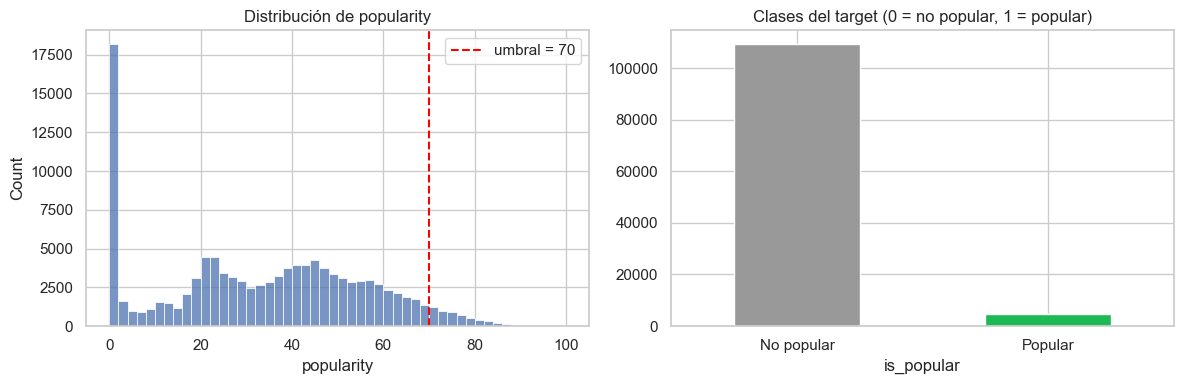

In [3]:
# Gráfico 1: distribución de popularity (con el umbral) y balance de clases del target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["popularity"], bins=50, ax=ax[0])
ax[0].axvline(THRESHOLD_POPULAR, color="red", ls="--", label=f"umbral = {THRESHOLD_POPULAR}")
ax[0].set_title("Distribución de popularity"); ax[0].legend()
df["is_popular"].value_counts().sort_index().plot.bar(ax=ax[1], color=["#999", "#1DB954"])
ax[1].set_title("Clases del target (0 = no popular, 1 = popular)")
ax[1].set_xticklabels(["No popular", "Popular"], rotation=0)
plt.tight_layout(); plt.savefig(IMG_DIR / "01_target.png", dpi=120); plt.show()

## 4. Análisis exploratorio (EDA)

### 4.1 Calidad de datos
Revisamos nulos, valores en cero que parecen errores y canciones repetidas.
Lo clave: una misma canción puede aparecer en varios géneros (mismo `track_id`), lo que obliga a separar train/test por canción.

In [4]:
# Calidad de datos: nulos, ceros sospechosos y canciones repetidas
nulos = df.isna().sum()
print("Columnas con nulos:\n", nulos[nulos > 0], "\n")

print("Valores en cero que podrían ser errores o datos faltantes:")
print(f"  popularity == 0     : {(df['popularity'] == 0).sum():,} ({(df['popularity'] == 0).mean():.1%})")
print(f"  tempo == 0          : {(df['tempo'] == 0).sum():,}")
print(f"  time_signature == 0 : {(df['time_signature'] == 0).sum():,}")
print(f"  duration_ms == 0    : {(df['duration_ms'] == 0).sum():,}\n")

# Canciones repetidas (riesgo de fuga de datos si el split fuera aleatorio)
n_dup_rows = df["track_id"].duplicated(keep=False).sum()
print(f"Filas cuyo track_id aparece más de una vez: {n_dup_rows:,} ({n_dup_rows/len(df):.1%})")
print(f"Tracks únicos: {df['track_id'].nunique():,} de {len(df):,} filas")
print(f"Tracks únicos populares: {df.loc[df.is_popular == 1, 'track_id'].nunique():,} vs filas populares: {df['is_popular'].sum():,}")
print(f"Géneros: {df['track_genre'].nunique()} | filas por género (min-max): {df['track_genre'].value_counts().min()}-{df['track_genre'].value_counts().max()}")

Columnas con nulos:
 artists       1
album_name    1
track_name    1
dtype: int64 

Valores en cero que podrían ser errores o datos faltantes:
  popularity == 0     : 16,020 (14.1%)
  tempo == 0          : 157
  time_signature == 0 : 163
  duration_ms == 0    : 1

Filas cuyo track_id aparece más de una vez: 40,900 (35.9%)
Tracks únicos: 89,741 de 114,000 filas
Tracks únicos populares: 2,734 vs filas populares: 4,846
Géneros: 114 | filas por género (min-max): 1000-1000


### 4.2 Ceros en `popularity` por género
Los ceros se concentran en ciertos géneros (jazz, iranian, romance, soul, latin, country). Es poco probable que sean canciones realmente sin oyentes:
podrían ser datos sin puntuar. Los mantenemos, pero lo declaramos como limitación del target.

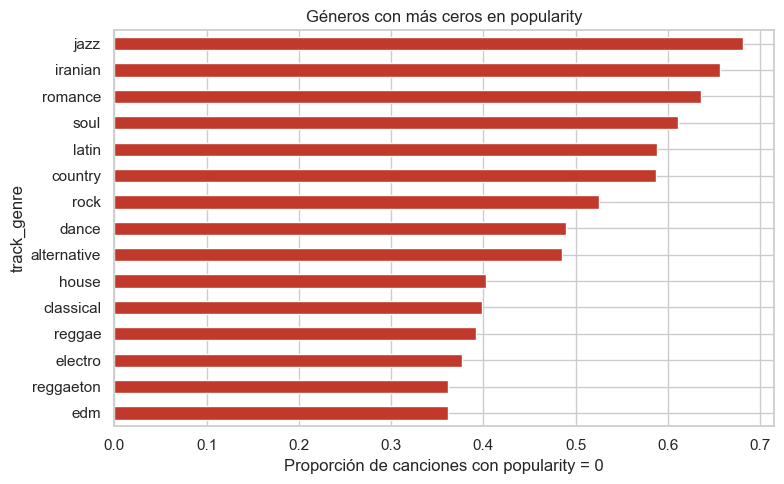

In [5]:
# Gráfico 2: porcentaje de canciones con popularity = 0 en los 15 géneros más afectados
ceros = (df["popularity"] == 0).groupby(df["track_genre"]).mean().sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
ceros.sort_values().plot.barh(color="#c0392b")
plt.xlabel("Proporción de canciones con popularity = 0"); plt.title("Géneros con más ceros en popularity")
plt.tight_layout(); plt.savefig(IMG_DIR / "02_ceros_por_genero.png", dpi=120); plt.show()

### 4.3 Variables de audio vs. popularidad
Las canciones populares son algo más fuertes (`loudness`) y bailables, y menos acústicas e instrumentales.
Pero las diferencias son pequeñas y ninguna correlación (Spearman) supera |0,08|: ninguna variable sola predice bien la popularidad.

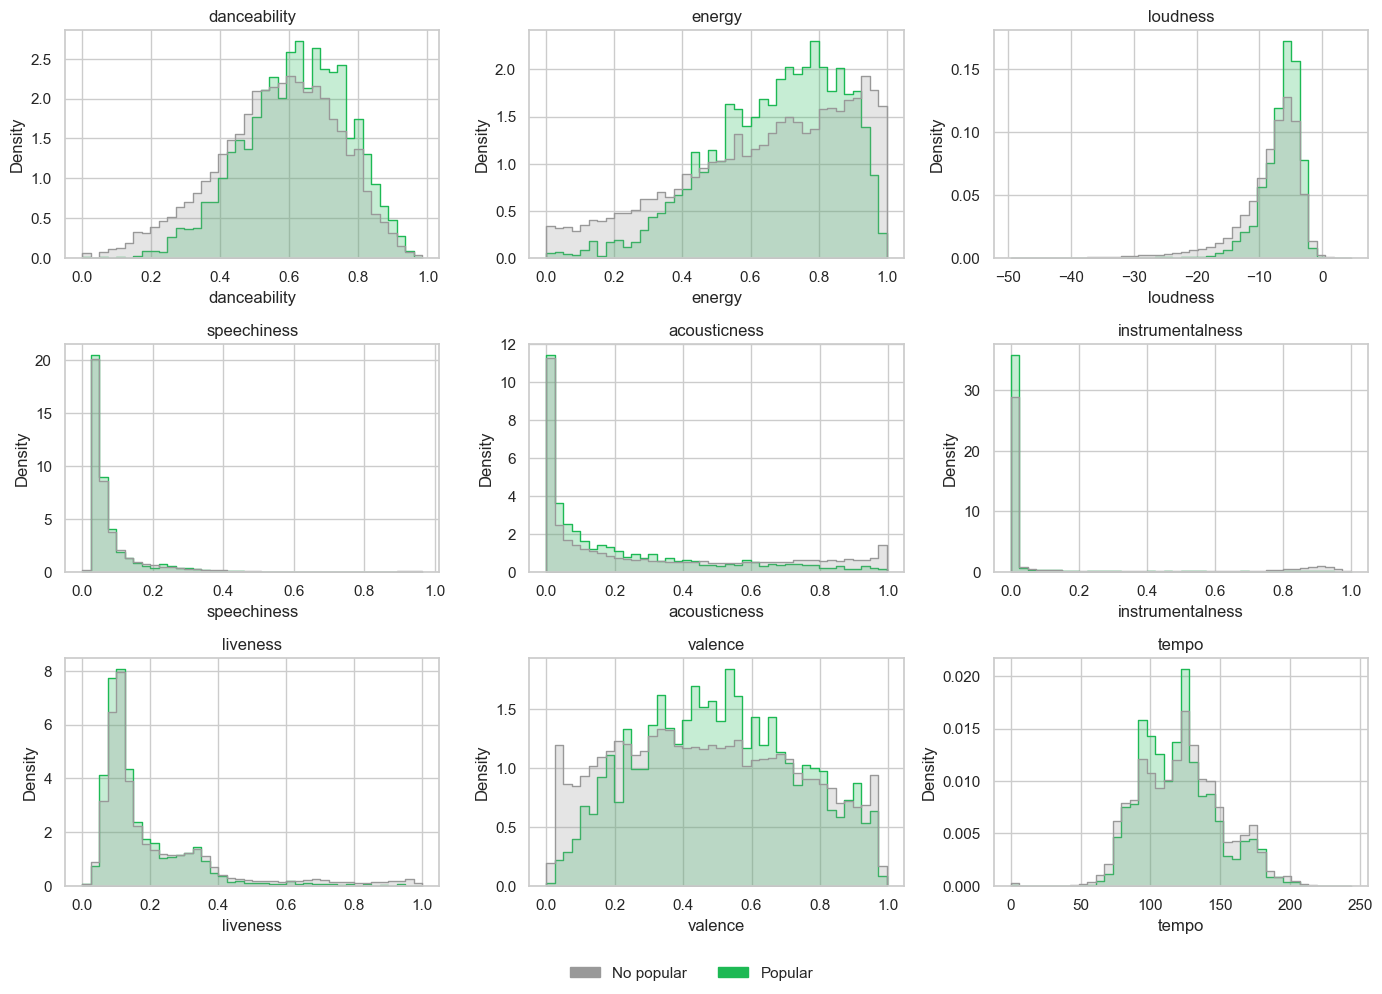

is_popular,0,1
danceability,0.564,0.619
energy,0.640,0.675
loudness,-8.334,-6.561
speechiness,0.085,0.076
acousticness,0.319,0.217
instrumentalness,0.161,0.035
liveness,0.215,0.171
valence,0.473,0.505
tempo,122.244,119.978


In [6]:
# Gráfico 3: distribución de cada variable de audio, separando populares y no populares
audio_cols = ["danceability", "energy", "loudness", "speechiness", "acousticness",
              "instrumentalness", "liveness", "valence", "tempo"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), audio_cols):
    sns.histplot(data=df, x=col, hue="is_popular", stat="density", common_norm=False,
                 element="step", bins=40, palette=["#999", "#1DB954"], ax=ax, legend=False)
    ax.set_title(col)
# Leyenda manual (colores fijos: gris = no popular, verde = popular)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#999", label="No popular"), Patch(color="#1DB954", label="Popular")],
           loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.savefig(IMG_DIR / "03_audio_por_clase.png", dpi=120); plt.show()

# Medias por clase para comparar numéricamente
df.groupby("is_popular")[audio_cols].mean().T.round(3)

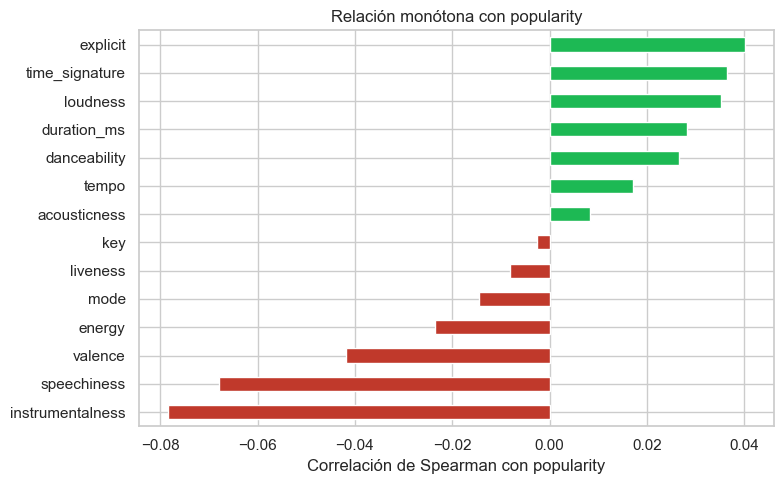

In [7]:
# Gráfico 4: correlación de Spearman de cada variable con popularity
num_cols = audio_cols + ["duration_ms", "key", "mode", "time_signature"]
tmp = df[num_cols].copy(); tmp["explicit"] = df["explicit"].astype(int)
corr = tmp.corrwith(df["popularity"], method="spearman").sort_values()
plt.figure(figsize=(8, 5))
corr.plot.barh(color=["#c0392b" if v < 0 else "#1DB954" for v in corr])
plt.xlabel("Correlación de Spearman con popularity"); plt.title("Relación monótona con popularity")
plt.tight_layout(); plt.savefig(IMG_DIR / "04_correlacion.png", dpi=120); plt.show()

### 4.4 Género y contenido explícito
El género es la variable más informativa: `pop` tiene 28 % de canciones populares y 26 de los 114 géneros no tienen ninguna.
Las canciones explícitas son populares el doble de veces (8,5 % vs 3,9 %).

Géneros sin ninguna canción popular: 26 de 114


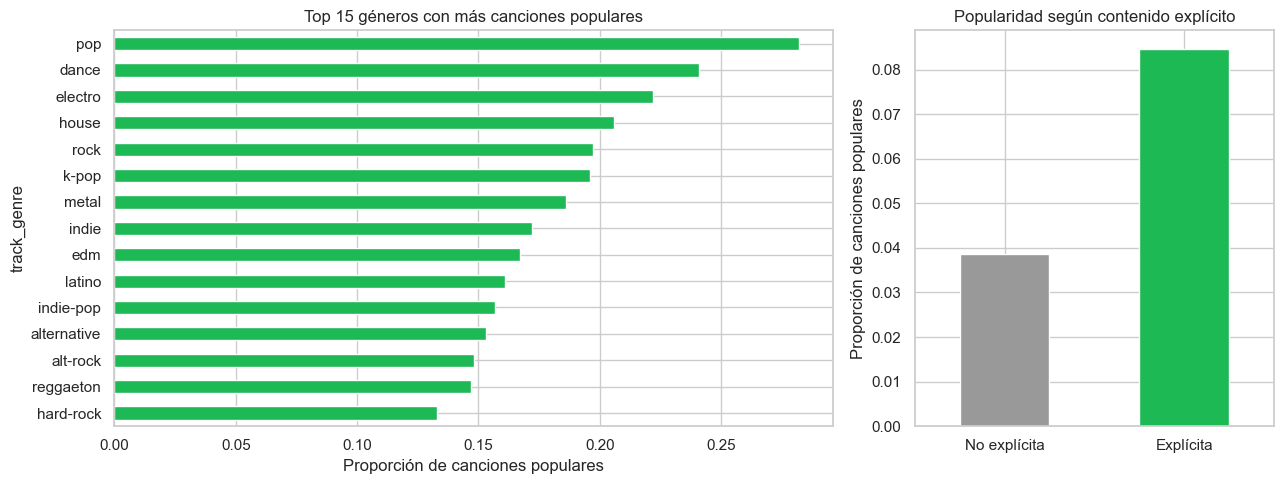

In [8]:
# Gráfico 5: % de canciones populares por género (top 15) y por contenido explícito
por_genero = df.groupby("track_genre")["is_popular"].mean().sort_values(ascending=False)
print(f"Géneros sin ninguna canción popular: {(por_genero == 0).sum()} de {len(por_genero)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 1]})
por_genero.head(15).sort_values().plot.barh(ax=ax[0], color="#1DB954")
ax[0].set_xlabel("Proporción de canciones populares"); ax[0].set_title("Top 15 géneros con más canciones populares")
df.groupby("explicit")["is_popular"].mean().rename({False: "No explícita", True: "Explícita"}).plot.bar(ax=ax[1], color=["#999", "#1DB954"])
ax[1].set_ylabel("Proporción de canciones populares"); ax[1].set_xlabel(""); ax[1].set_title("Popularidad según contenido explícito")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)
plt.tight_layout(); plt.savefig(IMG_DIR / "05_popular_por_genero.png", dpi=120); plt.show()

## 5. Preparación de datos

- **Se descartan** identificadores y texto (`track_id`, nombres, álbum, `artists`): `artists` haría que el modelo aprenda *quién* es famoso, no *qué* hace popular a una canción.
- **Se usan** 9 variables de audio, `duration_ms`, `key`, `mode`, `time_signature`, `explicit` y `track_genre` (categórica nativa de XGBoost, sin escalado ni one-hot).
- **Split 60/20/20** (train/validación/test) agrupado por `track_id` y estratificado por clase, para que una canción no quede en dos conjuntos a la vez.
- **Preparación específica por modelo:** Random Forest recibe `track_genre` con *One-Hot Encoding* (scikit-learn no acepta categóricas nativas); K-Means usa solo variables numéricas continuas, estandarizadas, y no usa el target.

In [9]:
# Define variables predictoras (X), targets (clasificación y regresión) y grupos para el split
DROP_COLS = ["Unnamed: 0", "track_id", "track_name", "album_name", "artists"]
TARGET_CLF, TARGET_REG = "is_popular", "popularity"

X = df.drop(columns=DROP_COLS + [TARGET_CLF, TARGET_REG]).copy()
X["explicit"] = X["explicit"].astype(int)               # bool -> 0/1
X["track_genre"] = X["track_genre"].astype("category")  # XGBoost la usa como categórica nativa
y_clf, y_reg = df[TARGET_CLF], df[TARGET_REG]
groups = df["track_id"]

def split_estratificado_por_grupo(y, groups, n_splits, seed=SEED):
    # Toma el primer fold de StratifiedGroupKFold: ~1/n_splits de los datos, sin compartir track_id
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups))

# 80 % train+val / 20 % test
trval_idx, test_idx = split_estratificado_por_grupo(y_clf, groups, n_splits=5)
# Del 80 %: 75 % train / 25 % validación (early stopping y elección de umbral) -> 60/20/20 global
tr_rel, val_rel = split_estratificado_por_grupo(y_clf.iloc[trval_idx], groups.iloc[trval_idx], n_splits=4)
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

X_train, X_val, X_test = X.iloc[train_idx], X.iloc[val_idx], X.iloc[test_idx]
yc_train, yc_val, yc_test = y_clf.iloc[train_idx], y_clf.iloc[val_idx], y_clf.iloc[test_idx]
yr_train, yr_val, yr_test = y_reg.iloc[train_idx], y_reg.iloc[val_idx], y_reg.iloc[test_idx]

# Verificación: ningún track_id compartido entre conjuntos
g_tr, g_val, g_te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
assert not (g_tr & g_val) and not (g_tr & g_te) and not (g_val & g_te), "Hay fuga de track_id entre conjuntos"

# Tamaño y % de populares en cada conjunto (deben ser similares)
resumen = pd.DataFrame({
    "filas": [len(X_train), len(X_val), len(X_test)],
    "% populares": [yc_train.mean(), yc_val.mean(), yc_test.mean()],
}, index=["train", "validación", "test"])
resumen["% populares"] = resumen["% populares"].map("{:.2%}".format)
resumen

,filas,% populares
train,68400,4.25%
validación,22800,4.25%
test,22800,4.25%


## 6. Modelado

### 6.1 XGBoost · Clasificación (modelo principal)
XGBoost captura relaciones no lineales entre variables y maneja género como categórica; justo lo que necesitamos, porque ninguna variable de audio explica sola la popularidad.
`scale_pos_weight` compensa el desbalance (~4 % populares) y `early_stopping_rounds` evita el sobreajuste. Los hiperparámetros son un punto de partida, aún sin afinar.

In [10]:
# Línea base: un modelo que siempre predice "no popular" (referencia mínima a superar)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, yc_train)
print("Línea base (siempre 'no popular') -> F1 en test:", round(f1_score(yc_test, dummy.predict(X_test)), 4))

# Peso de la clase popular = negativos / positivos (compensa el desbalance)
scale_pos_weight = (yc_train == 0).sum() / (yc_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

# Entrena XGBoost; el conjunto de validación decide cuándo detener el entrenamiento
xgb_clf = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    early_stopping_rounds=50,
    tree_method="hist",
    enable_categorical=True,
    random_state=SEED,
    n_jobs=-1,
)
xgb_clf.fit(X_train, yc_train, eval_set=[(X_val, yc_val)], verbose=False)
print("Mejor iteración:", xgb_clf.best_iteration)

Línea base (siempre 'no popular') -> F1 en test: 0.0
scale_pos_weight = 22.52
Mejor iteración: 184


**Umbral de decisión.** Con `scale_pos_weight` las probabilidades se desplazan, por lo que 0,5 rara vez es el mejor corte.
Elegimos el umbral que maximiza F1 en validación y lo evaluamos una sola vez en test.

In [11]:
# Probabilidades de "popular" en validación y test
proba_val = xgb_clf.predict_proba(X_val)[:, 1]
proba_test = xgb_clf.predict_proba(X_test)[:, 1]

# Elige el umbral que maximiza F1 en VALIDACIÓN (nunca en test)
prec, rec, thr = precision_recall_curve(yc_val, proba_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"Umbral óptimo (validación): {best_thr:.3f}  | F1 validación = {f1s.max():.4f}")

def metricas_clf(y_true, proba, umbral):
    # Calcula Precision, Recall, F1 (con el umbral dado) y PR-AUC (independiente del umbral)
    pred = (proba >= umbral).astype(int)
    return {"Umbral": round(umbral, 3),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "PR-AUC": average_precision_score(y_true, proba)}

# Tabla de resultados en TEST: umbral estándar (0.5) vs umbral óptimo
tabla = pd.DataFrame({
    "XGBoost (umbral 0.5)": metricas_clf(yc_test, proba_test, 0.5),
    "XGBoost (umbral óptimo)": metricas_clf(yc_test, proba_test, best_thr),
}).T
print(f"Prevalencia en test (PR-AUC de un modelo aleatorio): {yc_test.mean():.4f}")
tabla.round(4)

Umbral óptimo (validación): 0.727  | F1 validación = 0.3100
Prevalencia en test (PR-AUC de un modelo aleatorio): 0.0425


,Umbral,Precision,Recall,F1,PR-AUC
XGBoost (umbral 0.5),0.500,0.1540,0.7461,0.2553,0.2394
XGBoost (umbral óptimo),0.727,0.2296,0.4634,0.3070,0.2394


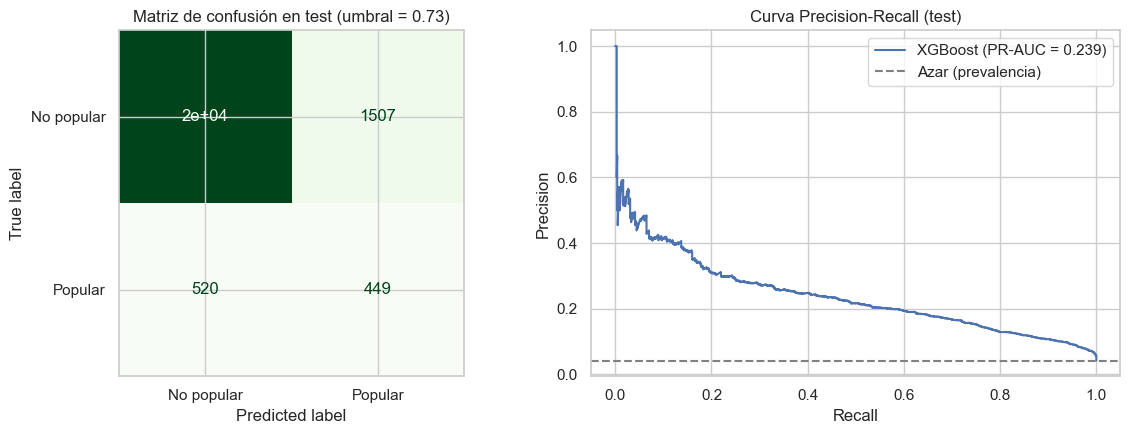

In [12]:
# Matriz de confusión (umbral óptimo) y curva Precision-Recall en test
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

pred_opt = (proba_test >= best_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(yc_test, pred_opt),
                       display_labels=["No popular", "Popular"]).plot(ax=ax[0], cmap="Greens", colorbar=False)
ax[0].set_title(f"Matriz de confusión en test (umbral = {best_thr:.2f})")

p, r, _ = precision_recall_curve(yc_test, proba_test)
ax[1].plot(r, p, label=f"XGBoost (PR-AUC = {average_precision_score(yc_test, proba_test):.3f})")
ax[1].axhline(yc_test.mean(), color="gray", ls="--", label="Azar (prevalencia)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Curva Precision-Recall (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG_DIR / "06_resultados_clasificacion.png", dpi=120); plt.show()

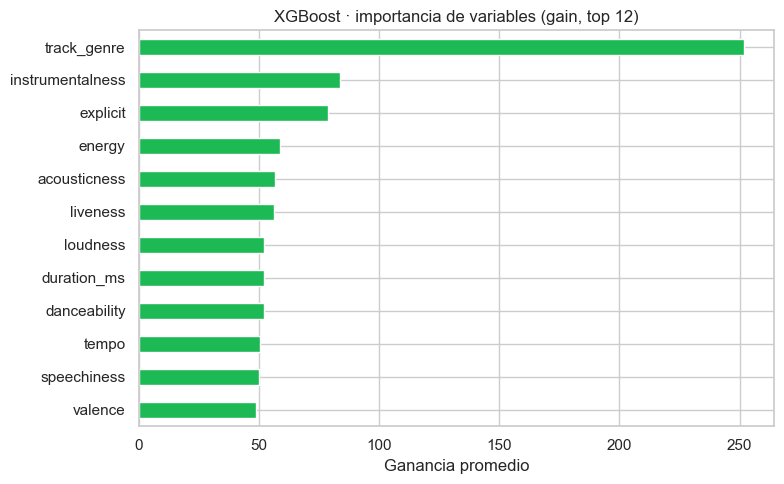

In [13]:
# Importancia de variables según XGBoost (ganancia promedio, top 12)
imp = pd.Series(xgb_clf.get_booster().get_score(importance_type="gain")).sort_values(ascending=True)
imp.tail(12).plot.barh(figsize=(8, 5), color="#1DB954")
plt.title("XGBoost · importancia de variables (gain, top 12)"); plt.xlabel("Ganancia promedio")
plt.tight_layout(); plt.savefig(IMG_DIR / "07_importancia_variables.png", dpi=120); plt.show()

### 6.2 Regresión complementaria (MAE / RMSE)
Mismo algoritmo y mismos conjuntos, pero prediciendo `popularity` (0–100).
Entrega el error promedio en puntos de popularidad, más fácil de comunicar al negocio.

In [14]:
# Línea base de regresión: predecir siempre el promedio de popularity
dummy_reg = DummyRegressor(strategy="mean").fit(X_train, yr_train)

# XGBoost de regresión (misma configuración base que el clasificador)
xgb_reg = XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    eval_metric="rmse", early_stopping_rounds=50, tree_method="hist",
    enable_categorical=True, random_state=SEED, n_jobs=-1,
)
xgb_reg.fit(X_train, yr_train, eval_set=[(X_val, yr_val)], verbose=False)

def metricas_reg(y_true, pred):
    # MAE y RMSE en puntos de popularidad
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred))}

# Tabla de resultados en TEST
tabla_reg = pd.DataFrame({
    "Línea base (promedio)": metricas_reg(yr_test, dummy_reg.predict(X_test)),
    "XGBoost": metricas_reg(yr_test, xgb_reg.predict(X_test)),
}).T
tabla_reg.round(3)

,MAE,RMSE
Línea base (promedio),18.911,22.330
XGBoost,12.269,17.404


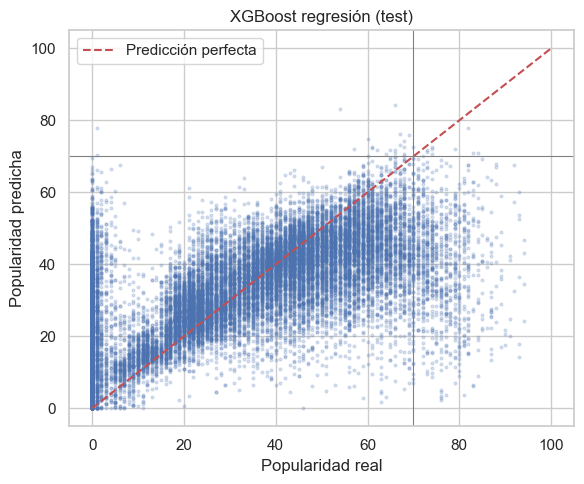

In [15]:
# Popularidad real vs predicha en test (la diagonal roja sería una predicción perfecta)
pred_reg = np.clip(xgb_reg.predict(X_test), 0, 100)
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, pred_reg, s=4, alpha=0.2)
plt.plot([0, 100], [0, 100], "r--", label="Predicción perfecta")
plt.axhline(THRESHOLD_POPULAR, color="gray", lw=0.8); plt.axvline(THRESHOLD_POPULAR, color="gray", lw=0.8)
plt.xlabel("Popularidad real"); plt.ylabel("Popularidad predicha"); plt.title("XGBoost regresión (test)")
plt.legend(); plt.tight_layout(); plt.savefig(IMG_DIR / "08_regresion_real_vs_predicho.png", dpi=120); plt.show()

In [16]:
# Guarda los modelos entrenados en models/ (formato JSON nativo de XGBoost)
xgb_clf.save_model(MODELS_DIR / "xgb_clasificador.json")
xgb_reg.save_model(MODELS_DIR / "xgb_regresor.json")
print("Modelos guardados en:", MODELS_DIR.resolve())

Modelos guardados en: D:\Cosas-Mia\Enginner Data\Semestre 6\ML\Exp_2\Prueba\Spotify\models


### 6.3 Modelo supervisado 2: Random Forest

Para comparar XGBoost con otro algoritmo supervisado usamos **Random Forest**.

**Por qué este modelo.** Ambos están basados en árboles de decisión, pero aprenden de forma distinta: Random Forest entrena muchos árboles independientes sobre muestras aleatorias de los datos y promedia sus votos (*bagging*), mientras que XGBoost entrena los árboles en secuencia y cada uno corrige los errores del anterior (*boosting*). Si ambos llegan a conclusiones parecidas, los patrones encontrados son más confiables.

**Diferencia de preparación.** scikit-learn no acepta variables categóricas nativas, así que `track_genre` se transforma con *One-Hot Encoding* (una columna 0/1 por género). XGBoost, en cambio, la usa directamente.

**Para que la comparación sea justa:**
- Mismos conjuntos de train, validación y test, y mismo tratamiento del desbalance (`class_weight="balanced"`).
- Cada modelo usa **su propio umbral de decisión**, elegido maximizando F1 en validación. El umbral de XGBoost no sirve para Random Forest, porque las probabilidades de cada modelo tienen otra escala.
- Como métrica que no depende del umbral se compara además el **PR-AUC**.

In [17]:
# ---------------------------------------------------------------------------
# 6.3 Modelo supervisado 2: Random Forest (clasificación)
# ---------------------------------------------------------------------------
# Random Forest de scikit-learn no acepta variables categóricas nativas, por lo que
# `track_genre` se codifica con One-Hot Encoding. El resto de las columnas pasa sin cambios.
# El codificador se ajusta SOLO con train y luego se aplica a validación y test (sin fuga de datos).

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = ["track_genre"]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]
print(f"Columnas numéricas: {len(numeric_cols)} | categóricas: {len(categorical_cols)} {categorical_cols}")

# handle_unknown="ignore": si apareciera un género no visto en train, no falla (queda en ceros)
preprocessor = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols)],
    remainder="passthrough",
)
X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)
print(f"Columnas antes del One-Hot: {X_train.shape[1]} -> después: {X_train_encoded.shape[1]}")

# Hiperparámetros (punto de partida, sin afinar, igual que en XGBoost):
#   n_estimators=500        -> cantidad de árboles del bosque.
#   max_depth=None          -> sin límite de profundidad; el sobreajuste se controla con las dos siguientes.
#   min_samples_split=5     -> mínimo de canciones que debe tener un nodo para poder dividirse.
#   min_samples_leaf=2      -> mínimo de canciones por hoja.
#   class_weight="balanced" -> da más peso a la clase popular (~4 %) para compensar el desbalance.
#   random_state=SEED       -> resultados reproducibles.
#   n_jobs=-1               -> usa todos los núcleos del computador.
rf_clf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
print("\nEntrenando Random Forest...")
rf_clf.fit(X_train_encoded, yc_train)
print("Entrenamiento completado")

# Probabilidad de "popular": en validación (para elegir el umbral) y en test (evaluación final)
rf_proba_val = rf_clf.predict_proba(X_val_encoded)[:, 1]
rf_proba = rf_clf.predict_proba(X_test_encoded)[:, 1]

# Umbral propio de Random Forest: el que maximiza F1 en VALIDACIÓN (mismo criterio que XGBoost)
prec_rf, rec_rf, thr_rf = precision_recall_curve(yc_val, rf_proba_val)
f1s_rf = 2 * prec_rf[:-1] * rec_rf[:-1] / (prec_rf[:-1] + rec_rf[:-1] + 1e-12)
rf_thr = thr_rf[np.argmax(f1s_rf)]
print(f"Umbral óptimo de Random Forest (validación): {rf_thr:.3f} | F1 validación = {f1s_rf.max():.4f}")

# Predicción de clase en test con ese umbral
rf_pred = (rf_proba >= rf_thr).astype(int)
print(f"Canciones evaluadas en test: {len(rf_pred):,}")

Columnas numéricas: 14 | categóricas: 1 ['track_genre']
Columnas antes del One-Hot: 15 -> después: 128

Entrenando Random Forest...
Entrenamiento completado
Umbral óptimo de Random Forest (validación): 0.319 | F1 validación = 0.2875
Canciones evaluadas en test: 22,800


COMPARACIÓN EN TEST: XGBoost vs Random Forest
  Métrica  XGBoost  Random Forest
   Umbral   0.7270         0.3190
Precision   0.2296         0.1989
   Recall   0.4634         0.4892
       F1   0.3070         0.2828
   PR-AUC   0.2394         0.1850
Referencia: un modelo aleatorio tendría PR-AUC = prevalencia = 0.0425
Mejor F1: XGBoost | Mejor PR-AUC: XGBoost


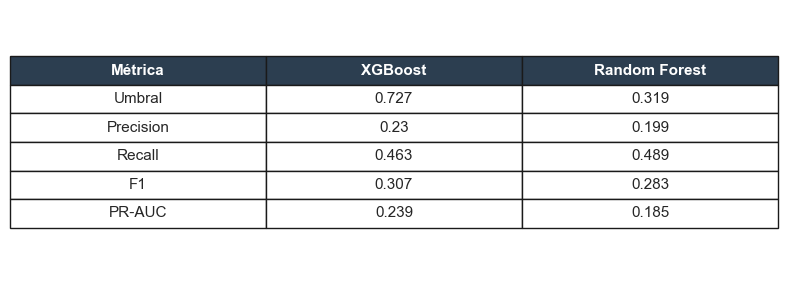

In [18]:
# ---------------------------------------------------------------------------
# Comparación de modelos supervisados: XGBoost vs Random Forest (conjunto de TEST)
# ---------------------------------------------------------------------------
# Cada modelo se evalúa con su propio umbral (elegido en validación) usando la misma función
# `metricas_clf`. El PR-AUC no depende del umbral, por lo que es la comparación más directa.

metricas_xgb = metricas_clf(yc_test, proba_test, best_thr)
metricas_rf = metricas_clf(yc_test, rf_proba, rf_thr)

claves = ["Umbral", "Precision", "Recall", "F1", "PR-AUC"]
comparacion = pd.DataFrame({
    "Métrica": claves,
    "XGBoost": [metricas_xgb[k] for k in claves],
    "Random Forest": [metricas_rf[k] for k in claves],
})

print("=" * 60)
print("COMPARACIÓN EN TEST: XGBoost vs Random Forest")
print("=" * 60)
print(comparacion.round(4).to_string(index=False))
print("=" * 60)
print(f"Referencia: un modelo aleatorio tendría PR-AUC = prevalencia = {yc_test.mean():.4f}")

# Mejor modelo según cada criterio
mejor_f1 = "XGBoost" if metricas_xgb["F1"] >= metricas_rf["F1"] else "Random Forest"
mejor_pr = "XGBoost" if metricas_xgb["PR-AUC"] >= metricas_rf["PR-AUC"] else "Random Forest"
print(f"Mejor F1: {mejor_f1} | Mejor PR-AUC: {mejor_pr}")

# Guarda la tabla como imagen para el informe
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")
tabla_img = ax.table(cellText=comparacion.round(3).values, colLabels=comparacion.columns,
                     cellLoc="center", loc="center")
tabla_img.auto_set_font_size(False)
tabla_img.set_fontsize(11)
tabla_img.scale(1.2, 1.5)
for j in range(len(comparacion.columns)):                      # encabezado oscuro
    tabla_img[(0, j)].set_facecolor("#2c3e50")
    tabla_img[(0, j)].set_text_props(weight="bold", color="white")
plt.tight_layout()
plt.savefig(IMG_DIR / "09_comparacion_modelos.png", dpi=120, bbox_inches="tight")
plt.show()

Top 10 variables según Random Forest (género agrupado):
track_genre (total)    0.2466
instrumentalness       0.0819
energy                 0.0769
loudness               0.0759
acousticness           0.0740
liveness               0.0712
duration_ms            0.0708
danceability           0.0642
speechiness            0.0603
tempo                  0.0595


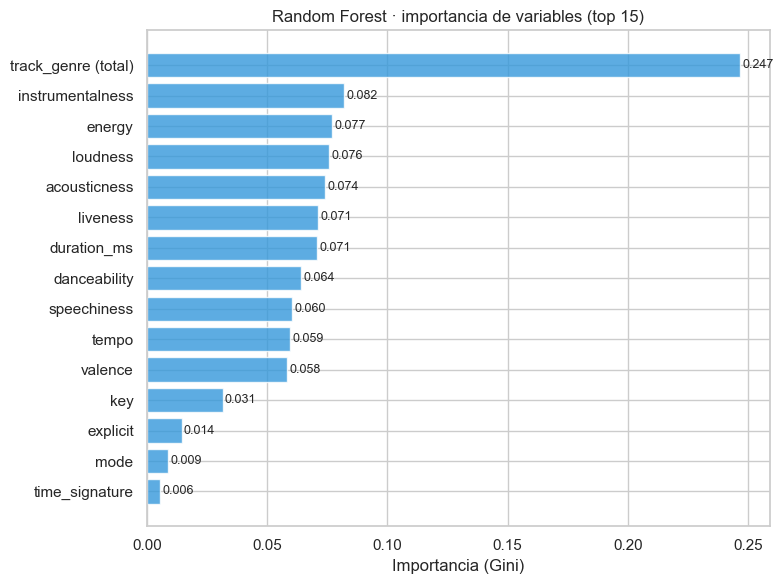

In [19]:
# ---------------------------------------------------------------------------
# Importancia de variables: Random Forest (importancia de Gini)
# ---------------------------------------------------------------------------
# Los nombres se obtienen del propio `preprocessor`, que los entrega en el MISMO orden de las
# columnas transformadas (primero los géneros one-hot y luego las variables numéricas).
nombres = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
imp_rf = pd.Series(rf_clf.feature_importances_, index=nombres)

# Los 114 géneros one-hot se suman en una sola variable para poder compararla con las demás
es_genero = imp_rf.index.str.startswith("track_genre_")
imp_agrupada = imp_rf[~es_genero].copy()
imp_agrupada["track_genre (total)"] = imp_rf[es_genero].sum()
imp_agrupada = imp_agrupada.sort_values(ascending=False)

print("Top 10 variables según Random Forest (género agrupado):")
print(imp_agrupada.head(10).round(4).to_string())

# Gráfico del top 15
top = imp_agrupada.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color="#3498db", alpha=0.8)
for y_pos, valor in enumerate(top.values):                     # valor numérico junto a cada barra
    ax.text(valor + 0.001, y_pos, f"{valor:.3f}", va="center", fontsize=9)
ax.set_xlabel("Importancia (Gini)")
ax.set_title("Random Forest · importancia de variables (top 15)")
plt.tight_layout()
plt.savefig(IMG_DIR / "10_importancia_rf.png", dpi=120, bbox_inches="tight")
plt.show()

### 6.4 Análisis no supervisado: segmentación de canciones con K-Means

**Pregunta de negocio.** ¿Existen "perfiles musicales" naturales en el catálogo y alguno concentra más (o menos) canciones populares que el promedio? Si es así, el equipo de promoción puede priorizar por perfil además de usar el ranking del modelo.

**Por qué K-Means.** Es una técnica de segmentación simple, rápida con 114.000 canciones y fácil de explicar al negocio: cada grupo se describe por el promedio de sus variables de audio. El algoritmo **no ve la popularidad**; esta se usa solo después, para interpretar los grupos.

**Cómo se define K.** Se comparan K = 2 a 10 con el método del codo (inercia) y la silueta.

In [20]:
# ---------------------------------------------------------------------------
# 6.4 Preparación de los datos para K-Means
# ---------------------------------------------------------------------------
# Se usan variables numéricas continuas que describen cómo suena la canción.
# Quedan fuera: popularity / is_popular (los grupos no deben depender del target), los identificadores
# y las variables categóricas o binarias (track_genre, key, mode, explicit), porque la distancia
# euclidiana que usa K-Means no es adecuada para ellas.

from sklearn.preprocessing import StandardScaler

variables_clustering = [
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "duration_ms", "time_signature",
]
print(f"Variables para clustering ({len(variables_clustering)}): {variables_clustering}")

# Se usa TODO el dataset: no hay train/test porque aquí no se predice nada.
# Limitación: las canciones que aparecen en varios géneros se cuentan más de una vez.
X_clustering = df[variables_clustering].copy()

# El dataset no tiene nulos en estas columnas; el relleno con la mediana es solo una precaución.
print(f"Valores nulos: {X_clustering.isna().sum().sum()}")
X_clustering = X_clustering.fillna(X_clustering.median())

# Estandarización (media 0, desviación 1): sin ella, variables con escala grande como
# duration_ms o tempo dominarían la distancia y las de escala 0-1 casi no influirían.
scaler = StandardScaler()
X_clustering_scaled = scaler.fit_transform(X_clustering)
print(f"Matriz escalada: {X_clustering_scaled.shape[0]:,} canciones x {X_clustering_scaled.shape[1]} variables")

Variables para clustering (11): ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'time_signature']
Valores nulos: 0
Matriz escalada: 114,000 canciones x 11 variables


Calculando inercia y silueta para cada K...
K= 2 | Inercia =    1,027,730 | Silueta = 0.2532
K= 3 | Inercia =      933,956 | Silueta = 0.1433
K= 4 | Inercia =      868,973 | Silueta = 0.1464
K= 5 | Inercia =      801,562 | Silueta = 0.1532
K= 6 | Inercia =      748,585 | Silueta = 0.1587
K= 7 | Inercia =      699,084 | Silueta = 0.1637
K= 8 | Inercia =      654,820 | Silueta = 0.1710
K= 9 | Inercia =      626,812 | Silueta = 0.1717
K=10 | Inercia =      598,786 | Silueta = 0.1712

K sugerido por el codo: 5 (silueta = 0.153)
K con mejor silueta:   2 (silueta = 0.253)


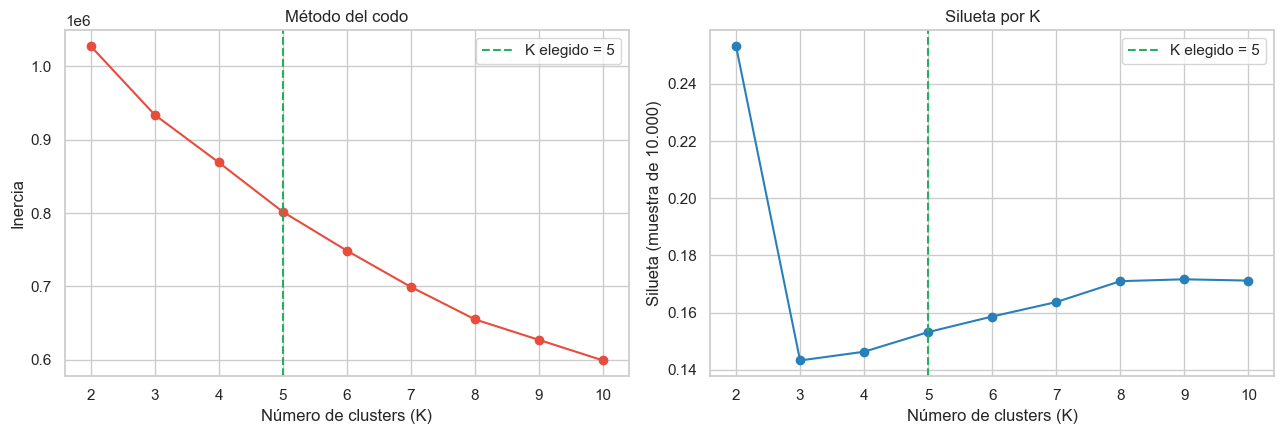

In [21]:
# ---------------------------------------------------------------------------
# Selección de K: método del codo (inercia) y silueta
# ---------------------------------------------------------------------------
#   Inercia: suma de distancias al centroide; siempre baja al aumentar K, se busca el "codo".
#   Silueta: de -1 a 1; mide qué tan separado y compacto está cada grupo (más alto = mejor).

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_range = list(range(2, 11))
inercias, siluetas = [], []

# La silueta es costosa (compara todos los pares de puntos), por eso se calcula sobre una muestra
# de 10.000 canciones. La muestra se sortea una sola vez para que todos los K se comparen igual.
n_muestra = min(10_000, X_clustering_scaled.shape[0])
muestra = np.random.RandomState(SEED).choice(X_clustering_scaled.shape[0], size=n_muestra, replace=False)

print("Calculando inercia y silueta para cada K...")
for k in k_range:
    # init="k-means++": centroides iniciales bien separados | n_init=10: se repite 10 veces y se
    # conserva la mejor solución | max_iter=300: tope de iteraciones | random_state: reproducible
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
    etiquetas = km.fit_predict(X_clustering_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_clustering_scaled[muestra], etiquetas[muestra]))
    print(f"K={k:2d} | Inercia = {km.inertia_:>12,.0f} | Silueta = {siluetas[-1]:.4f}")

# Detección automática del codo: se normalizan K e inercia a [0, 1] y se busca el punto más
# alejado de la recta que une el primer y el último punto de la curva.
x = np.array(k_range, dtype=float)
y = np.array(inercias, dtype=float)
x_norm = (x - x.min()) / (x.max() - x.min())
y_norm = (y - y.min()) / (y.max() - y.min() + 1e-12)
codo_k = int(x[np.argmax(np.abs(y_norm - (1 - x_norm)))])

mejor_sil_k = k_range[int(np.argmax(siluetas))]
print(f"\nK sugerido por el codo: {codo_k} (silueta = {siluetas[k_range.index(codo_k)]:.3f})")
print(f"K con mejor silueta:   {mejor_sil_k} (silueta = {max(siluetas):.3f})")

# Gráficos: codo (con K elegido) y silueta
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(k_range, inercias, marker="o", color="#e74c3c")
ax[0].axvline(codo_k, color="#27ae60", ls="--", label=f"K elegido = {codo_k}")
ax[0].set_xlabel("Número de clusters (K)"); ax[0].set_ylabel("Inercia")
ax[0].set_title("Método del codo"); ax[0].set_xticks(k_range); ax[0].legend()
ax[1].plot(k_range, siluetas, marker="o", color="#2980b9")
ax[1].axvline(codo_k, color="#27ae60", ls="--", label=f"K elegido = {codo_k}")
ax[1].set_xlabel("Número de clusters (K)"); ax[1].set_ylabel("Silueta (muestra de 10.000)")
ax[1].set_title("Silueta por K"); ax[1].set_xticks(k_range); ax[1].legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "11_metodo_codo.png", dpi=120, bbox_inches="tight")
plt.show()

**Decisión sobre K.** La silueta es mayor con K = 2 (≈ 0,25) que con K = 5 (≈ 0,15). Sin embargo, al revisar los perfiles de los grupos, K = 2 ofrece una separación demasiado general para el objetivo del análisis. El método del codo sugiere K = 5, y los perfiles obtenidos con ese valor son distinguibles e interpretables para el negocio. Por ello, **se elige K = 5 como compromiso entre granularidad e interpretabilidad**, reconociendo que el codo no es concluyente.

**Limitación:** una silueta cercana a 0,15 sugiere una separación débil entre grupos y posible solapamiento. Los clusters se interpretan como una segmentación descriptiva, no como categorías rígidas ni como una regla de decisión automática; pueden orientar la priorización, pero no sustituir la evaluación de cada caso.

114,000 canciones asignadas a 5 clusters

Cluster 0: 8,377 canciones (7.3%)
Cluster 1: 42,319 canciones (37.1%)
Cluster 2: 24,608 canciones (21.6%)
Cluster 3: 8,043 canciones (7.1%)
Cluster 4: 30,653 canciones (26.9%)

Perfil promedio de cada cluster:
         danceability  energy  acousticness  valence    tempo
cluster                                                      
0               0.531   0.748         0.344    0.500  121.233
1               0.689   0.736         0.187    0.682  120.695
2               0.543   0.387         0.668    0.406  113.584
3               0.351   0.185         0.839    0.183  103.577
4               0.483   0.806         0.063    0.311  136.151

Popularidad por cluster:
         pct_populares  total_populares  popularidad_promedio  veces_la_prevalencia
cluster                                                                            
0                 1.47              123                  34.1                  0.35
1                 6.32             2

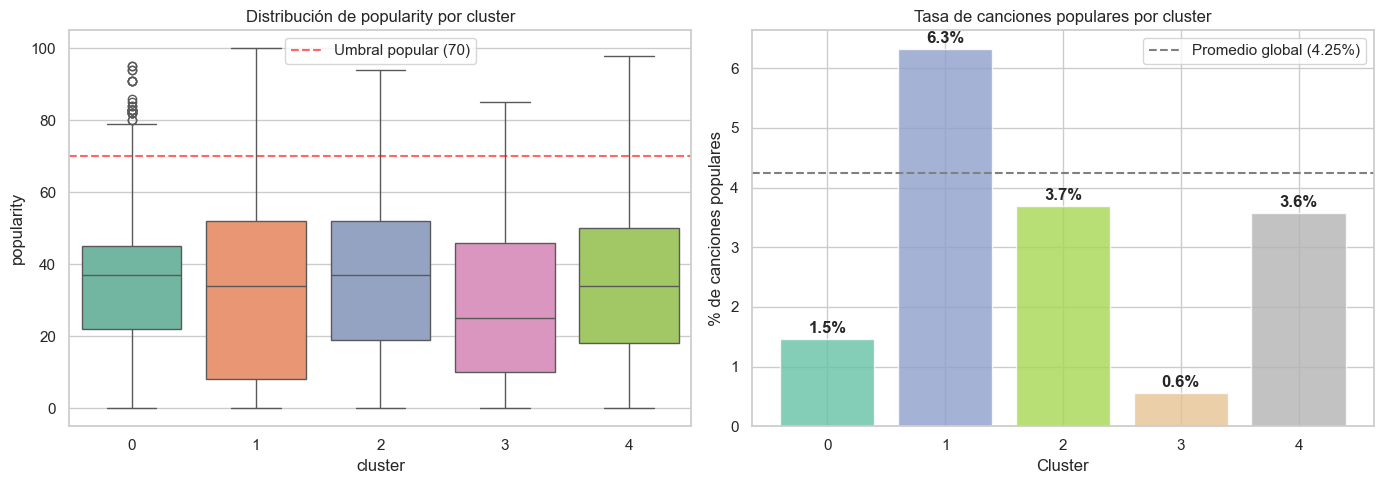

In [22]:
# ---------------------------------------------------------------------------
# Clustering final (K elegido por el codo) y relación de cada grupo con la popularidad
# ---------------------------------------------------------------------------
K_OPTIMO = codo_k   # viene de la celda anterior; no se fija a mano

kmeans_final = KMeans(n_clusters=K_OPTIMO, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
cluster_labels = kmeans_final.fit_predict(X_clustering_scaled)
assert len(cluster_labels) == len(df), "Las etiquetas no coinciden con el número de filas"
df["cluster"] = cluster_labels

# Tamaño de cada cluster
distribucion = df["cluster"].value_counts().sort_index()
print(f"{len(df):,} canciones asignadas a {K_OPTIMO} clusters\n")
for c, n in distribucion.items():
    print(f"Cluster {c}: {n:,} canciones ({n / len(df):.1%})")

# Perfil promedio de cada cluster (variables más distintivas)
perfil_clusters = df.groupby("cluster")[variables_clustering].mean()
print("\nPerfil promedio de cada cluster:")
print(perfil_clusters[["danceability", "energy", "acousticness", "valence", "tempo"]].round(3).to_string())

# Popularidad por cluster. "Veces la prevalencia" = % populares del cluster / % populares global (~4,25 %)
prevalencia_global = df["is_popular"].mean()
pop_por_cluster = df.groupby("cluster").agg(
    pct_populares=("is_popular", "mean"),
    total_populares=("is_popular", "sum"),
    popularidad_promedio=("popularity", "mean"),
)
pop_por_cluster["veces_la_prevalencia"] = pop_por_cluster["pct_populares"] / prevalencia_global
pop_por_cluster["pct_populares"] = (pop_por_cluster["pct_populares"] * 100).round(2)
pop_por_cluster = pop_por_cluster.round({"popularidad_promedio": 1, "veces_la_prevalencia": 2})
print("\nPopularidad por cluster:")
print(pop_por_cluster.to_string())

# Gráficos: distribución de popularity por cluster y % de populares por cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="cluster", y="popularity", palette="Set2", ax=axes[0])
axes[0].axhline(THRESHOLD_POPULAR, color="red", ls="--", alpha=0.6, label="Umbral popular (70)")
axes[0].set_title("Distribución de popularity por cluster"); axes[0].legend()

tasas = pop_por_cluster["pct_populares"].sort_index()
axes[1].bar(tasas.index, tasas.values, color=plt.cm.Set2(np.linspace(0, 1, len(tasas))), alpha=0.8)
axes[1].axhline(prevalencia_global * 100, color="gray", ls="--", label=f"Promedio global ({prevalencia_global:.2%})")
for cluster_id, tasa in tasas.items():                          # etiqueta sobre la barra de SU cluster
    axes[1].text(cluster_id, tasa + 0.1, f"{tasa:.1f}%", ha="center", fontweight="bold")
axes[1].set_xticks(tasas.index)
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("% de canciones populares")
axes[1].set_title("Tasa de canciones populares por cluster"); axes[1].legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "12_analisis_clusters.png", dpi=120, bbox_inches="tight")
plt.show()

In [23]:
# ---------------------------------------------------------------------------
# Caracterización de cada cluster: rasgos distintivos y nombre del perfil
# ---------------------------------------------------------------------------
# Un rasgo es "distintivo" si se aleja del promedio global. Solo se comparan variables en escala 0-1,
# porque tempo, duración y loudness tienen otras escalas y distorsionarían la comparación.
import joblib

vars_01 = ["danceability", "energy", "speechiness", "acousticness", "instrumentalness", "liveness", "valence"]
perfil_global = df[vars_01].mean()

def nombre_perfil(p):
    # Reglas simples sobre el perfil promedio del cluster, evaluadas en orden (la primera que se cumple gana).
    # Los umbrales se fijaron mirando los perfiles de la celda anterior, para que cada grupo tenga un nombre distinto.
    if p["liveness"] > 0.5:
        return "En vivo"                        # grabaciones en directo (liveness muy alta)
    if p["instrumentalness"] > 0.5:
        return "Instrumental / Ambiental"       # sin voz, acústica y de baja energía
    if p["acousticness"] > 0.5 and p["energy"] < 0.5:
        return "Acústico / Íntimo"
    if p["energy"] > 0.7 and p["danceability"] > 0.6 and p["valence"] > 0.55:
        return "Bailable / Alegre"
    if p["energy"] > 0.7 and p["valence"] < 0.4:
        return "Intenso / Oscuro"               # muy enérgica pero de ánimo bajo
    return "Mixto"

for cluster_id in range(K_OPTIMO):
    p = perfil_clusters.loc[cluster_id]
    sub = df[df["cluster"] == cluster_id]
    dif = (p[vars_01] - perfil_global)
    print("=" * 70)
    print(f"CLUSTER {cluster_id} · perfil: {nombre_perfil(p)}")
    print(f"Tamaño: {len(sub):,} canciones ({len(sub) / len(df):.1%}) | "
          f"populares: {sub['is_popular'].mean():.2%} | popularidad promedio: {sub['popularity'].mean():.1f}")
    print("Rasgos sobre el promedio global:", ", ".join(f"{v} ({d:+.2f})" for v, d in dif.nlargest(3).items()))
    print("Rasgos bajo el promedio global: ", ", ".join(f"{v} ({d:+.2f})" for v, d in dif.nsmallest(3).items()))
    print(f"Contexto: {p['tempo']:.0f} BPM | {p['duration_ms'] / 60000:.1f} min | {p['loudness']:.1f} dB")

# Guarda el nombre del perfil en cada canción
nombres_clusters = {c: nombre_perfil(perfil_clusters.loc[c]) for c in range(K_OPTIMO)}
df["perfil"] = df["cluster"].map(nombres_clusters)

# Guarda el escalador y el K-Means en models/ (son archivos livianos; Random Forest no se guarda
# porque con 500 árboles profundos el archivo pesa cientos de MB)
joblib.dump(scaler, MODELS_DIR / "scaler_clustering.joblib")
joblib.dump(kmeans_final, MODELS_DIR / "kmeans_clusters.joblib")
print("\nModelos de segmentación guardados en:", MODELS_DIR.resolve())

CLUSTER 0 · perfil: En vivo
Tamaño: 8,377 canciones (7.3%) | populares: 1.47% | popularidad promedio: 34.1
Rasgos sobre el promedio global: liveness (+0.52), speechiness (+0.11), energy (+0.11)
Rasgos bajo el promedio global:  instrumentalness (-0.09), danceability (-0.04), valence (+0.03)
Contexto: 121 BPM | 3.9 min | -7.5 dB
CLUSTER 1 · perfil: Bailable / Alegre
Tamaño: 42,319 canciones (37.1%) | populares: 6.32% | popularidad promedio: 33.0
Rasgos sobre el promedio global: valence (+0.21), danceability (+0.12), energy (+0.09)
Rasgos bajo el promedio global:  acousticness (-0.13), instrumentalness (-0.11), liveness (-0.05)
Contexto: 121 BPM | 3.5 min | -6.3 dB
CLUSTER 2 · perfil: Acústico / Íntimo
Tamaño: 24,608 canciones (21.6%) | populares: 3.70% | popularidad promedio: 34.3
Rasgos sobre el promedio global: acousticness (+0.35), danceability (-0.02), speechiness (-0.03)
Rasgos bajo el promedio global:  energy (-0.25), instrumentalness (-0.10), valence (-0.07)
Contexto: 114 BPM | 3.

## 7. Interpretación de resultados y recomendaciones

La tabla siguiente reúne las métricas finales (todas medidas en el conjunto de **test**, que se usó una sola vez) y los perfiles de canciones.

In [24]:
# ---------------------------------------------------------------------------
# Resumen consolidado de resultados (sirve para completar la tabla del README)
# ---------------------------------------------------------------------------
# 1) Clasificación: ambos modelos con su umbral elegido en validación + línea base de referencia
resumen_clf = pd.DataFrame({"XGBoost": metricas_xgb, "Random Forest": metricas_rf}).T.round(4)
resumen_clf["Veces sobre el azar (PR-AUC / prevalencia)"] = (resumen_clf["PR-AUC"] / yc_test.mean()).round(1)
print(f"CLASIFICACIÓN (test) | prevalencia = {yc_test.mean():.4f} | línea base F1 = 0.0")
print(resumen_clf.to_string())

# 2) Regresión (XGBoost vs promedio)
print("\nREGRESIÓN (test)")
print(tabla_reg.round(3).to_string())
mejora_mae = 1 - tabla_reg.loc["XGBoost", "MAE"] / tabla_reg.loc["Línea base (promedio)", "MAE"]
print(f"Reducción del MAE frente a la línea base: {mejora_mae:.0%}")

# 3) Segmentación: tamaño y % de populares por perfil
resumen_perfiles = df.groupby("perfil").agg(
    canciones=("is_popular", "size"),
    pct_catalogo=("is_popular", lambda s: len(s) / len(df) * 100),
    pct_populares=("is_popular", lambda s: s.mean() * 100),
).round(2).sort_values("pct_populares", ascending=False)
resumen_perfiles["veces_la_prevalencia"] = (resumen_perfiles["pct_populares"] / (prevalencia_global * 100)).round(2)
print("\nPERFILES MUSICALES (K-Means)")
print(resumen_perfiles.to_string())

CLASIFICACIÓN (test) | prevalencia = 0.0425 | línea base F1 = 0.0
               Umbral  Precision  Recall      F1  PR-AUC  Veces sobre el azar (PR-AUC / prevalencia)
XGBoost         0.727     0.2296  0.4634  0.3070  0.2394                                         5.6
Random Forest   0.319     0.1989  0.4892  0.2828  0.1850                                         4.4

REGRESIÓN (test)
                          MAE    RMSE
Línea base (promedio)  18.911  22.330
XGBoost                12.269  17.404
Reducción del MAE frente a la línea base: 35%

PERFILES MUSICALES (K-Means)
                          canciones  pct_catalogo  pct_populares  veces_la_prevalencia
perfil                                                                                
Bailable / Alegre             42319         37.12           6.32                  1.49
Acústico / Íntimo             24608         21.59           3.70                  0.87
Intenso / Oscuro              30653         26.89           3.57           

### 7.1 Modelos supervisados (clasificación)

- **XGBoost supera con claridad a la línea base y al azar.** Con el umbral óptimo (0,727) obtiene Precision 0,23, Recall 0,46, F1 0,31 y PR-AUC 0,239, frente a un PR-AUC de 0,0425 que tendría un modelo aleatorio: ordena las canciones **unas 5,6 veces mejor que el azar**. La línea base ("nadie es popular") tiene F1 = 0.
- **Qué significan Precision y Recall.** De cada 100 canciones que el modelo recomienda, unas 23 son realmente populares (contra 4 de cada 100 si se eligieran al azar), y el modelo detecta unas 46 de cada 100 canciones populares. Es una mejora real, pero **no es un modelo para decidir solo**: más de tres de cada cuatro recomendaciones no serán éxitos.
- **El umbral es una decisión de negocio.** Con 0,5 el Recall sube a 0,75 pero la Precision baja a 0,15; con 0,727 se equilibran. Con presupuesto limitado conviene el umbral alto (menos aciertos perdidos en canciones que no despegan); para explorar talento de forma amplia, uno más bajo.
- **Random Forest, evaluado con su propio umbral, queda cerca de XGBoost en F1 pero por debajo en PR-AUC (≈ 0,185 vs 0,239).** XGBoost ordena mejor las canciones, por lo que se mantiene como modelo principal. Que ambos algoritmos, de naturaleza distinta, lleguen a un nivel de desempeño parecido sugiere que el techo lo pone la información disponible y no el algoritmo.
- **Variables.** En Random Forest el **género** es la variable más importante: sumando sus 114 columnas aporta ≈ 23 % de la importancia, casi el triple que cualquier variable de audio individual. Las variables de audio se reparten el resto de forma pareja (cada una con ≈ 6–8 %), sin ninguna dominante. Es coherente con el EDA: el género es lo que más separa a las canciones populares, y ninguna característica de audio explica sola la popularidad (|Spearman| ≤ 0,08).

### 7.2 Regresión complementaria

XGBoost reduce el MAE de 18,9 a 12,3 puntos (−35 %) y el RMSE de 22,3 a 17,4 frente a predecir siempre el promedio. Un error típico de ~12 puntos es **demasiado grande para decidir si una canción cruza el umbral de 70**, pero sirve para ordenar canciones por potencial.

### 7.3 Segmentación no supervisada (K-Means, K = 5)

| Perfil | % del catálogo | % populares | Lectura |
|---|---|---|---|
| Bailable / Alegre | 37,1 % | 6,3 % | Concentra más éxitos: ≈ 1,5 veces el promedio (4,25 %). Es el perfil de las canciones populares del EDA: bailable, positivo, enérgico y fuerte (−6,3 dB). |
| Acústico / Íntimo | 21,6 % | 3,7 % | Algo bajo el promedio. |
| Intenso / Oscuro | 26,9 % | 3,6 % | Algo bajo el promedio; es el grupo más rápido (136 BPM) y de ánimo bajo. |
| En vivo | 7,3 % | 1,5 % | Muy bajo: las grabaciones en directo rara vez son populares. |
| Instrumental / Ambiental | 7,1 % | 0,6 % | El más bajo (≈ 0,13 veces el promedio). |

La silueta es baja (≈ 0,15), así que los perfiles se traslapan y deben leerse como **tendencias, no como reglas**: aun en el mejor perfil, 94 de cada 100 canciones no son populares.

### 7.4 Recomendaciones para el negocio

1. **Usar el modelo como ranking de apoyo.** Priorizar la revisión de las canciones con mayor probabilidad según XGBoost; con el umbral elegido, unas 23 de cada 100 recomendadas son éxitos, cinco veces más que al azar.
2. **Ajustar el umbral al presupuesto:** alto (0,73) para campañas costosas, más bajo (0,5) para exploración de talento.
3. **Combinar con el perfil musical.** Dar prioridad de promoción masiva al perfil *Bailable / Alegre* y tratar *Instrumental / Ambiental* y *En vivo* como nichos con otra estrategia (playlists temáticas), sin descartarlos por su baja tasa.
4. **No usar el modelo para rechazar artistas.** Evita reforzar el sesgo hacia géneros ya dominantes (pop, dance) y hacia artistas ya conocidos (por eso se excluyó `artists`).
5. **Para mejorar el desempeño** hace falta más información: artista, fecha de lanzamiento, presencia en playlists y marketing; además de revisar los ceros de `popularity` (14 % de las filas), que podrían ser datos sin puntuar, y afinar los hiperparámetros.